,Day,Hour,Weather,Traffic_Level
0,Monday,8,Sunny,3
1,Tuesday,9,Cloudy,4
2,Wednesday,10,Rainy,5
3,Thursday,11,Sunny,3
4,Friday,12,Cloudy,4
5,Saturday,13,Rainy,5
6,Sunday,14,Sunny,2


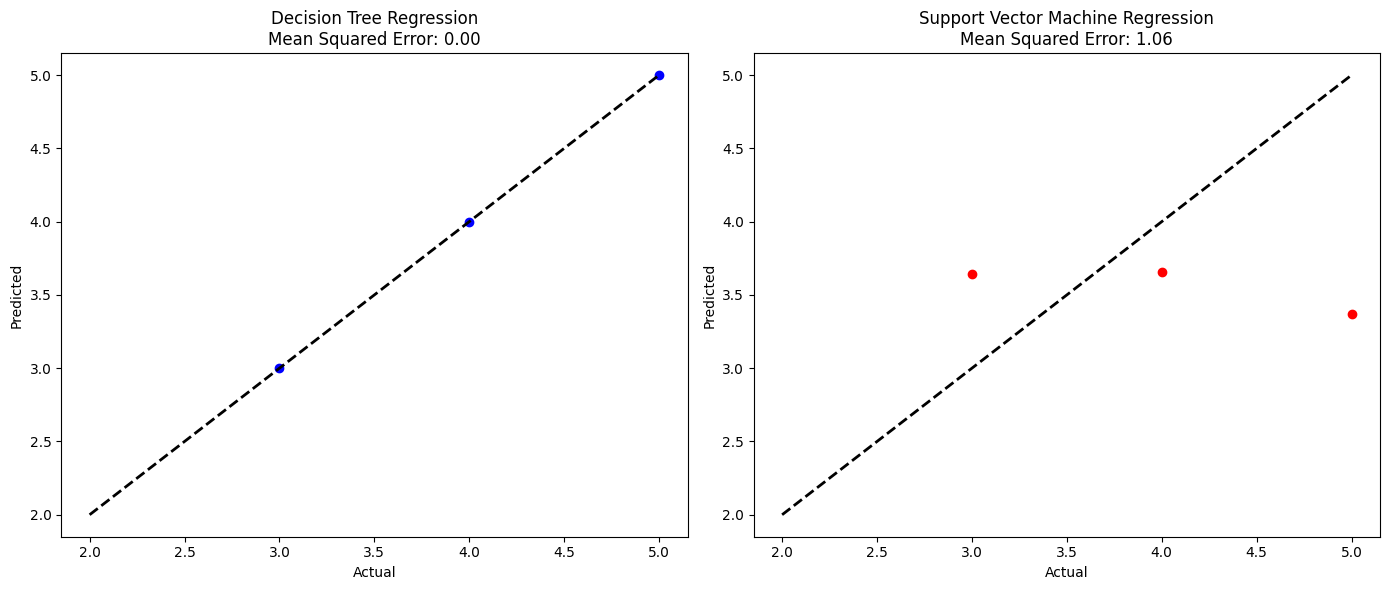

Mean Squared Error (Decision Tree): 0.0
Mean Squared Error (SVM): 1.064443944287495


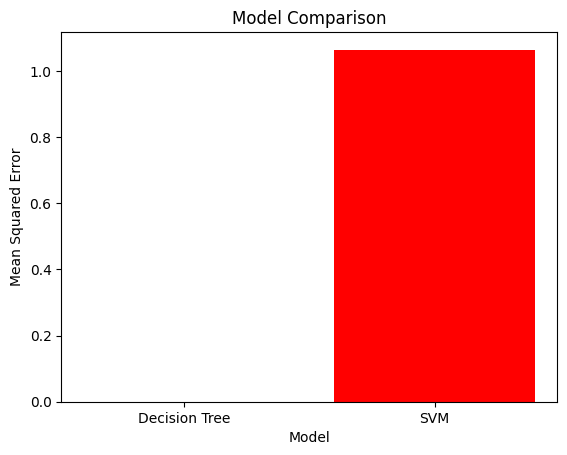

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

# Membaca dataset
df = pd.read_csv('jakarta_traffic.csv')
df_html = df.to_html()  # Move this line after reading the DataFrame
display(HTML(df_html))


# Mengubah fitur kategorikal menjadi numerik
df['Day'] = df['Day'].astype('category').cat.codes
df['Weather'] = df['Weather'].astype('category').cat.codes

# Memisahkan fitur dan label
X = df[['Day', 'Hour', 'Weather']]
y = df['Traffic_Level']

# Membagi data menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Decision Tree Model
dt_model = DecisionTreeRegressor()
dt_model.fit(X_train, y_train)
dt_y_pred = dt_model.predict(X_test)
dt_mse = mean_squared_error(y_test, dt_y_pred)

# SVM Model
svm_model = SVR()
svm_model.fit(X_train, y_train)
svm_y_pred = svm_model.predict(X_test)
svm_mse = mean_squared_error(y_test, svm_y_pred)

# Plotting the results
plt.figure(figsize=(14, 6))

# Plot for Decision Tree
plt.subplot(1, 2, 1)
plt.scatter(y_test, dt_y_pred, color='blue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Decision Tree Regression\nMean Squared Error: {dt_mse:.2f}')

# Plot for SVM
plt.subplot(1, 2, 2)
plt.scatter(y_test, svm_y_pred, color='red')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Support Vector Machine Regression\nMean Squared Error: {svm_mse:.2f}')

plt.tight_layout()
plt.show()

print(f"Mean Squared Error (Decision Tree): {dt_mse}")
print(f"Mean Squared Error (SVM): {svm_mse}")

# Correct the indentation for the following block
models = ['Decision Tree', 'SVM']
mse_values = [dt_mse, svm_mse]

plt.bar(models, mse_values, color=['blue', 'red'])
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.title('Model Comparison')
plt.show()